# Section 1: From TF-IDF to Sequence Models

## Why are we moving beyond TF-IDF?

In the previous lecture, we built a sentiment analysis pipeline using **TF-IDF + classical machine learning**.

That approach worked well because it converted each document into a fixed-length feature vector:

$$
\mathbf{x} \in \mathbb{R}^V
$$

where $V$ is the vocabulary size.

Each component measured the importance of a word in a document relative to the corpus.
This is powerful for many classification tasks.

But today we ask a deeper question:

> Does a document mean only **which words appear**, or also **the order in which they appear**?

## What TF-IDF captures well

TF-IDF is useful when:

- word importance matters
- document-level classification is the main goal
- order is less critical
- we want interpretable sparse features

For example, in sentiment classification:

- "excellent", "amazing", "worst", "poor"  
can already provide strong signal.

So TF-IDF is not "wrong" — it is simply **limited**.

## What TF-IDF misses

TF-IDF treats text mostly as a **bag of weighted words**.

So these two sentences become very similar:

1. **"not good"**
2. **"good"**

and these may also look close:

1. **"dog bites man"**
2. **"man bites dog"**

But meaning changes when order changes.

TF-IDF does not naturally model:

- word order
- local context
- evolving meaning across positions
- dependence of later words on earlier words

## Static representation vs dynamic representation

In TF-IDF, the whole sentence or document is compressed into one fixed vector:

$$
\mathbf{x}_{\text{doc}} = [x_1, x_2, \dots, x_V]
$$

This is a **static representation**.

In sequence models, we process tokens one step at a time:

$$
x_1, x_2, x_3, \dots, x_T
$$

and build an internal evolving representation:

$$
h_t = f(x_t, h_{t-1})
$$

So meaning is no longer treated as one frozen vector.
Instead, meaning is **updated through time** as the sequence unfolds.

## Example intuition

Consider the sentence:

> "I thought the movie would be great, but it was disappointing."

If we only count important words, both "great" and "disappointing" appear.

But the actual sentiment depends on how meaning develops across the sequence.

A sequence model can read:

- first: expectation is positive
- later: reversal happens with "but"
- final interpretation becomes negative

So in sequence modeling, meaning is not just present in words —
it is present in the **trajectory of words**.

## Why this matters for deep learning NLP

Many NLP tasks require order-sensitive understanding:

- next word prediction
- machine translation
- text generation
- speech / sequence labeling
- question answering
- summarization

These tasks require a model to remember what came before and use it while processing what comes next.

That is the motivation for recurrent sequence models.

## Bridge to recurrent models

So the transition is:

- **TF-IDF**: useful for document-level signals, but ignores sequence structure
- **Sequence models**: process text token by token and maintain evolving context

Vanilla RNN was one of the earliest deep learning solutions for this idea:

$$
h_t = \tanh(W_x x_t + W_h h_{t-1} + b)
$$

We already know this update rule.

Now the key question becomes:

> If RNN carries information forward through $h_t$, why does it still struggle on long sequences?

In [1]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

sentences = [
    "good movie",
    "not good movie",
    "man bites dog",
    "dog bites man"
]

vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(sentences)

df = pd.DataFrame(X.toarray(), columns=vectorizer.get_feature_names_out(), index=sentences)
df

,bites,dog,good,man,movie,not
good movie,0.00000,0.00000,0.707107,0.00000,0.707107,0.000000
not good movie,0.00000,0.00000,0.526405,0.00000,0.526405,0.667679
man bites dog,0.57735,0.57735,0.000000,0.57735,0.000000,0.000000
dog bites man,0.57735,0.57735,0.000000,0.57735,0.000000,0.000000


In [2]:
print("Vocabulary:", vectorizer.get_feature_names_out())
print("\nTF-IDF shape:", X.shape)

Vocabulary: ['bites' 'dog' 'good' 'man' 'movie' 'not']

TF-IDF shape: (4, 6)


In [3]:
for s in sentences:
    print(f"{s}  -->  {s.split()}")

good movie  -->  ['good', 'movie']
not good movie  -->  ['not', 'good', 'movie']
man bites dog  -->  ['man', 'bites', 'dog']
dog bites man  -->  ['dog', 'bites', 'man']


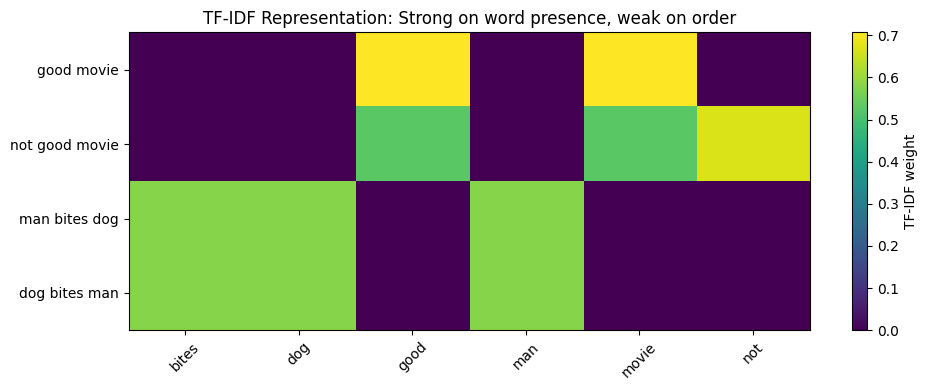

In [4]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 4))
plt.imshow(df.values, aspect='auto')
plt.xticks(np.arange(len(df.columns)), df.columns, rotation=45)
plt.yticks(np.arange(len(df.index)), df.index)
plt.colorbar(label="TF-IDF weight")
plt.title("TF-IDF Representation: Strong on word presence, weak on order")
plt.tight_layout()
plt.show()

### Concept Check

1. Why is TF-IDF called a static representation?

2. Give one NLP task where TF-IDF can work reasonably well.

3. Give one NLP task where TF-IDF is fundamentally limited.

4. Why are "good movie" and "not good movie" a useful comparison?

5. What is the main conceptual difference between:
   - document vector representation
   - sequence state representation

6. In one line, why do we need sequence models?

We now have the motivation for sequence modeling.

But a natural question remains:

If vanilla RNN already processes tokens one by one and carries a hidden state forward,  
why is that still not enough for long sequences?

To answer that, we next study the core weakness of vanilla RNN:
**long-term dependency failure and vanishing gradients.**

# Section 2: Why Vanilla RNN Fails on Long Dependencies

We already know the vanilla RNN hidden state update:

$$
h_t = \tanh(W_x x_t + W_h h_{t-1} + b)
$$

This looks reasonable:

- current state depends on current input
- current state also depends on previous hidden state

So in principle, information from the past can flow forward.

But in practice, vanilla RNN struggles when useful information must be preserved for many time steps.

## What is a long-term dependency?

A long-term dependency occurs when prediction at time $t$ depends on information that appeared much earlier.

Example:

> "I grew up in France ... I speak fluent ____"

To predict the missing word, the model may need to remember **France** across many intermediate words.

If the signal from the distant past fades away, the model cannot use it effectively.

So the core question is:

> Can the RNN really preserve relevant information over long distances?

## Forward view: repeated state transformation

If we expand the recurrence conceptually, each hidden state is built from repeated transformations:

$$
h_t \leftarrow h_{t-1} \leftarrow h_{t-2} \leftarrow \cdots \leftarrow h_1
$$

So old information is repeatedly passed through:

- matrix multiplication by $W_h$
- nonlinearity $\tanh(\cdot)$

This repeated transformation can gradually distort, shrink, or sometimes amplify signals.

## Backward view: gradients must also travel through time

During training, the loss at a later time step must send learning signal backward to earlier states.

If the total loss is

$$
L = \sum_{t=1}^{T} L_t
$$

then parameters influencing early time steps are updated through gradients that pass through many recurrent connections.

For example, if a loss at time $T$ depends on $h_T$, and $h_T$ depends on $h_{T-1}$, which depends on $h_{T-2}$, and so on, then:

$$
\frac{\partial L_T}{\partial h_k}
=
\frac{\partial L_T}{\partial h_T}
\frac{\partial h_T}{\partial h_{T-1}}
\frac{\partial h_{T-1}}{\partial h_{T-2}}
\cdots
\frac{\partial h_{k+1}}{\partial h_k}
$$

This is the chain rule through time.

## Local Jacobian of the recurrent step

Let

$$
a_t = W_x x_t + W_h h_{t-1} + b
$$

and

$$
h_t = \tanh(a_t)
$$

Then the derivative of $h_t$ with respect to $h_{t-1}$ is:

$$
\frac{\partial h_t}{\partial h_{t-1}}
=
\operatorname{diag}\left(1 - \tanh^2(a_t)\right) W_h
$$

So the backpropagated gradient is repeatedly multiplied by terms of the form:

$$
\operatorname{diag}\left(1 - \tanh^2(a_t)\right) W_h
$$

over many time steps.

## Why gradients vanish

Notice that for $\tanh(z)$:

$$
\frac{d}{dz}\tanh(z) = 1 - \tanh^2(z)
$$

and this derivative always lies in the interval:

$$
0 < 1 - \tanh^2(z) \leq 1
$$

When $\tanh(z)$ is saturated near $-1$ or $1$, the derivative becomes very small.

So if we repeatedly multiply many small factors, the overall gradient shrinks rapidly:

$$
\left\|
\frac{\partial L_T}{\partial h_k}
\right\|
\approx
\prod_{j=k+1}^{T}
\left\|
\frac{\partial h_j}{\partial h_{j-1}}
\right\|
\to 0
\quad \text{as } T-k \text{ grows}
$$

This is the **vanishing gradient problem**.

## Why gradients can also explode

The repeated product does not always shrink.

If the effective norm of the recurrent Jacobian is greater than $1$, then repeated multiplication can make gradients grow very large:

$$
\prod_{j=k+1}^{T}
\left\|
\frac{\partial h_j}{\partial h_{j-1}}
\right\|
\to \infty
$$

This is the **exploding gradient problem**.

So vanilla RNN training suffers from two opposite risks:

- gradients become too small to learn long-range dependence
- gradients become too large and destabilize training

## Role of $\tanh$ saturation

The problem is not only the matrix $W_h$.

The nonlinearity also matters.

For large positive or negative inputs:

$$
\tanh(z) \approx 1 \quad \text{or} \quad \tanh(z) \approx -1
$$

and then:

$$
1 - \tanh^2(z) \approx 0
$$

That means the neuron output changes very little even if the input changes.

So in saturated regions:

- forward information becomes compressed
- backward gradients become weak

This makes it difficult for the model to preserve or learn long-term effects.

## Interpretation: memory is fragile in vanilla RNN

Vanilla RNN does have memory, but it is an **unstable memory**.

Why?

Because remembered information must survive repeated nonlinear transformation.

There is no explicit mechanism saying:

- keep this information
- forget that information
- protect this signal from being overwritten

Everything is mixed into the same hidden state update.

## Core takeaway

Vanilla RNN is elegant, but for long sequences it has a structural weakness:

- information must pass through many recurrent steps
- gradients must also pass through those same steps
- repeated multiplication causes shrinking or amplification
- $\tanh$ saturation makes long-range learning even harder

So we need a recurrence mechanism with **better gradient flow** and **more controlled memory**.

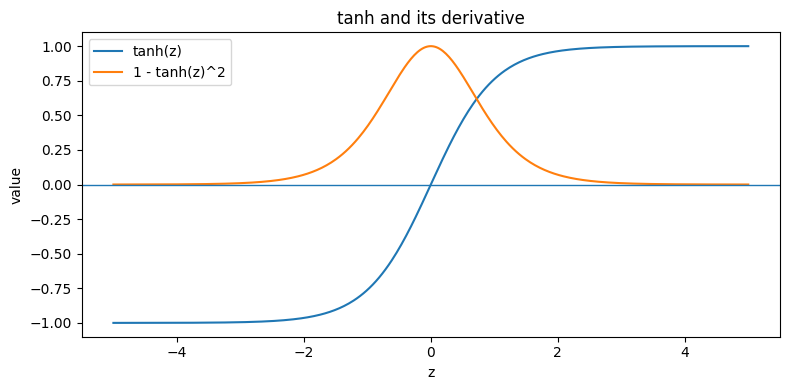

In [6]:
import numpy as np
import matplotlib.pyplot as plt

z = np.linspace(-5, 5, 400)
tanh_z = np.tanh(z)
tanh_derivative = 1 - tanh_z**2

plt.figure(figsize=(8, 4))
plt.plot(z, tanh_z, label='tanh(z)')
plt.plot(z, tanh_derivative, label="1 - tanh(z)^2")
plt.axhline(0, linewidth=1)
plt.title("tanh and its derivative")
plt.xlabel("z")
plt.ylabel("value")
plt.legend()
plt.tight_layout()
plt.show()

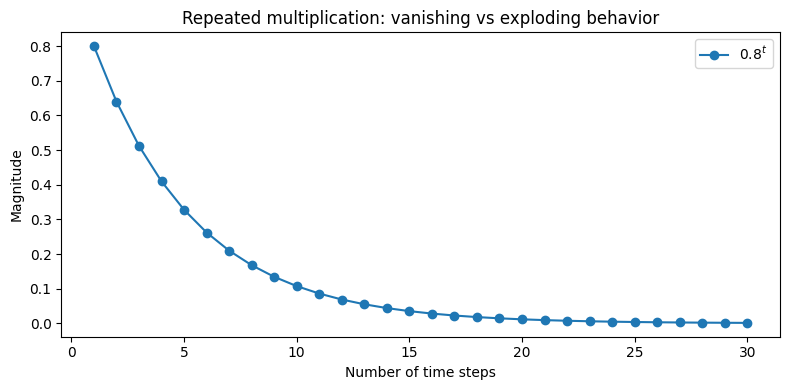

In [8]:
small_factor = 0.8
large_factor = 1.2

steps = np.arange(1, 31)
vanishing = small_factor ** steps
exploding = large_factor ** steps

plt.figure(figsize=(8, 4))
plt.plot(steps, vanishing, marker='o', label=r"$0.8^t$")
#plt.plot(steps, exploding, marker='o', label=r"$1.2^t$")
plt.title("Repeated multiplication: vanishing vs exploding behavior")
plt.xlabel("Number of time steps")
plt.ylabel("Magnitude")
plt.legend()
plt.tight_layout()
plt.show()

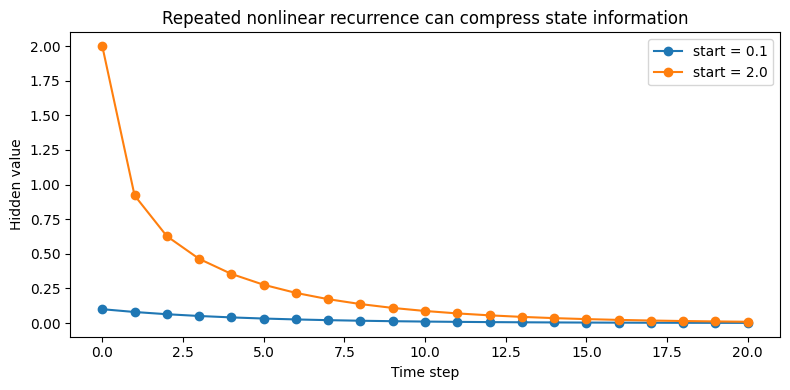

In [9]:
# A small toy recurrence to show how repeated transformation can wash out differences

def run_recurrence(h0, steps=20, w=0.8):
    hs = [h0]
    h = h0
    for _ in range(steps):
        h = np.tanh(w * h)
        hs.append(h)
    return np.array(hs)

steps = 20
h_a = run_recurrence(0.1, steps=steps, w=0.8)
h_b = run_recurrence(2.0, steps=steps, w=0.8)

plt.figure(figsize=(8, 4))
plt.plot(range(steps + 1), h_a, marker='o', label='start = 0.1')
plt.plot(range(steps + 1), h_b, marker='o', label='start = 2.0')
plt.title("Repeated nonlinear recurrence can compress state information")
plt.xlabel("Time step")
plt.ylabel("Hidden value")
plt.legend()
plt.tight_layout()
plt.show()

### Concept Check

1. What do we mean by a long-term dependency in sequence modeling?

2. Why does the gradient from a late loss have to pass through many time steps?

3. In one line, why can repeated multiplication cause vanishing gradients?

4. What is the derivative of $\tanh(z)$?

5. Why does $\tanh$ saturation worsen the vanishing gradient problem?

6. Can vanilla RNN suffer only from vanishing gradients, or also exploding gradients?

7. What is the deeper issue here:
   - lack of expressive power only
   - or difficulty of optimization through time?

We now understand the central weakness of vanilla RNN:

- memory must survive repeated nonlinear updates
- gradients must survive repeated Jacobian multiplication

So the next question is natural:

> Can we design a recurrent model where memory has a more protected path, and the model can decide what to keep, what to forget, and what to expose?

That leads us to **LSTM**.

# Section 3: LSTM as a Solution to Fragile Memory

Vanilla RNN stores everything inside a single hidden state:

$$
h_t = \tanh(W_x x_t + W_h h_{t-1} + b)
$$

This creates two problems:

- memory is repeatedly overwritten
- gradients must pass through repeated nonlinear transformations

LSTM introduces a more controlled memory mechanism.

The key idea is:

> Do not store everything in one place.  
> Separate **internal memory** from **visible state**, and control information flow using gates.

## Two states in LSTM

At each time step, LSTM maintains two different vectors:

- **cell state**: $c_t$
- **hidden state**: $h_t$

### Intuition

- $c_t$ is the long-term memory channel
- $h_t$ is the exposed working state used for output and interaction with the next step

So unlike vanilla RNN, LSTM does not force all information into one hidden vector.
It creates a more structured memory system.

## Why gating is needed

At every step, the model must answer questions like:

- What old information should be kept?
- What old information should be erased?
- What new information should be written?
- What part of memory should be revealed as output?

LSTM answers these questions using gates.

A gate is typically a sigmoid-based controller:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

Since

$$
0 < \sigma(z) < 1
$$

a gate can scale information continuously:

- near $0$: block it
- near $1$: pass it

## Step 1: Forget gate

The forget gate decides how much of the previous cell state should be retained.

$$
f_t = \sigma(W_f x_t + U_f h_{t-1} + b_f)
$$

Here:

- $x_t$ = current input
- $h_{t-1}$ = previous hidden state
- $f_t$ = forget gate vector

Interpretation:

- if a component of $f_t$ is close to $1$, keep that memory
- if a component is close to $0$, forget that memory

## Step 2: Input gate

The input gate decides how much new information should be written into memory.

$$
i_t = \sigma(W_i x_t + U_i h_{t-1} + b_i)
$$

This does not create content by itself.

It only decides:

> How strongly should the new candidate memory be allowed to enter?

## Step 3: Candidate memory

The model also computes a candidate memory content:

$$
\tilde{c}_t = \tanh(W_c x_t + U_c h_{t-1} + b_c)
$$

This is the new information proposal.

Interpretation:

- $i_t$ decides **how much to write**
- $\tilde{c}_t$ decides **what to write**

## Step 4: Cell state update

Now we combine retained old memory and gated new memory:

$$
c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t
$$

where $\odot$ denotes elementwise multiplication.

This is the most important LSTM equation.

It says:

- keep part of old memory: $f_t \odot c_{t-1}$
- add selected new memory: $i_t \odot \tilde{c}_t$

So memory is updated **additively**, not only through full nonlinear replacement.

## Why the additive update matters

In vanilla RNN, hidden state is repeatedly transformed through:

$$
h_t = \tanh(\cdots)
$$

So information is always pushed through a nonlinearity.

In LSTM, the cell state update contains a direct additive path:

$$
c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t
$$

This is important because the derivative of $c_t$ with respect to $c_{t-1}$ is approximately:

$$
\frac{\partial c_t}{\partial c_{t-1}} = f_t
$$

elementwise.

So if $f_t$ is near $1$, memory — and gradient — can pass through many steps much more easily.

This is the core reason LSTM improves long-range learning.

## Step 5: Output gate

Not all internal memory should be exposed at every step.

So LSTM uses an output gate:

$$
o_t = \sigma(W_o x_t + U_o h_{t-1} + b_o)
$$

This gate decides which part of the internal memory becomes visible in the hidden state.

## Step 6: Hidden state update

The hidden state is computed as:

$$
h_t = o_t \odot \tanh(c_t)
$$

Interpretation:

- $c_t$ is the internal memory
- $\tanh(c_t)$ gives a squashed version of memory
- $o_t$ decides how much of that memory is exposed

So:

- $c_t$ stores
- $h_t$ reveals

## Full LSTM equations together

The standard LSTM equations are:

$$
f_t = \sigma(W_f x_t + U_f h_{t-1} + b_f)
$$

$$
i_t = \sigma(W_i x_t + U_i h_{t-1} + b_i)
$$

$$
\tilde{c}_t = \tanh(W_c x_t + U_c h_{t-1} + b_c)
$$

$$
c_t = f_t \odot c_{t-1} + i_t \odot \tilde{c}_t
$$

$$
o_t = \sigma(W_o x_t + U_o h_{t-1} + b_o)
$$

$$
h_t = o_t \odot \tanh(c_t)
$$

## Cell state vs hidden state

### Cell state $c_t$
- internal memory channel
- designed for long-term information flow
- updated additively
- more protected from repeated distortion

### Hidden state $h_t$
- visible state passed to output layers
- also passed forward to help gate computation
- acts more like the current working representation

A useful mental model:

- $c_t$ = memory bank
- $h_t$ = what the model chooses to say right now

## Why LSTM is better than vanilla RNN

LSTM improves recurrence in two major ways:

1. **Controlled memory update**
   - not everything is overwritten at every step

2. **Improved gradient flow**
   - additive memory path reduces severe vanishing

This does not make LSTM perfect,
but it makes learning long dependencies far more practical.

## Important limitation

LSTM helps with long-range dependencies,
but it still processes sequence information step by step.

So later we will still ask:

- can recurrence parallelize efficiently?
- can it access distant tokens more directly?
- does fixed-size state remain a bottleneck?

Those questions will motivate the next lecture.

### Concept Check

1. Why is one hidden state not enough for robust long-term memory?

2. What is the role of the cell state $c_t$?

3. What does the forget gate $f_t$ control?

4. What is the difference between:
   - $i_t$
   - $\tilde{c}_t$

5. Write the LSTM cell update equation.

6. Why is the cell update called an additive memory path?

7. What does the output gate $o_t$ do?

8. In one line, how is $h_t$ different from $c_t$?

9. Why does LSTM usually handle long dependencies better than vanilla RNN?